# 03 · Modelagem, avaliação e explicabilidade

Resultados de `python -m src.training.train` (artefatos em `mlops/`). Produção: **Isolation Forest**
(não supervisionado). Benchmarks no mesmo teste: **LOF** e um **Gradient Boosting supervisionado**, que
mede o *teto* de sinal disponível nos rótulos.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if (Path.cwd().parent / "mlops").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SILVER = ROOT / "data/processed/silver"
GOLD = ROOT / "data/processed/gold"
REPORTS = ROOT / "mlops/reports"

In [2]:
m = json.loads((REPORTS / "metrics.json").read_text(encoding="utf-8"))
teste = pd.DataFrame(m["teste"]).T[["roc_auc", "pr_auc", "precisao_topk", "recall_topk", "lift_topk"]]
print(f"prevalência no teste: {next(iter(m['teste'].values()))['prevalencia']:.1%} | fila = top 10%")
teste

prevalência no teste: 24.8% | fila = top 10%


,roc_auc,pr_auc,precisao_topk,recall_topk,lift_topk
Isolation Forest (produção),0.9164,0.8456,0.9733,0.3925,3.92
LOF,0.8036,0.6376,0.8267,0.3333,3.33
Gradient Boosting supervisionado (teto),0.9741,0.9642,1.0,0.4032,4.03


In [3]:
pd.DataFrame(m["teste_fila_do_tamanho_da_prevalencia"]).T[["precisao_topk", "recall_topk", "fila_auditoria"]]

,precisao_topk,recall_topk,fila_auditoria
Isolation Forest (produção),0.7527,0.7527,186
LOF,0.629,0.629,186
Gradient Boosting supervisionado (teto),0.9032,0.9032,186


## Curvas precisão x recall

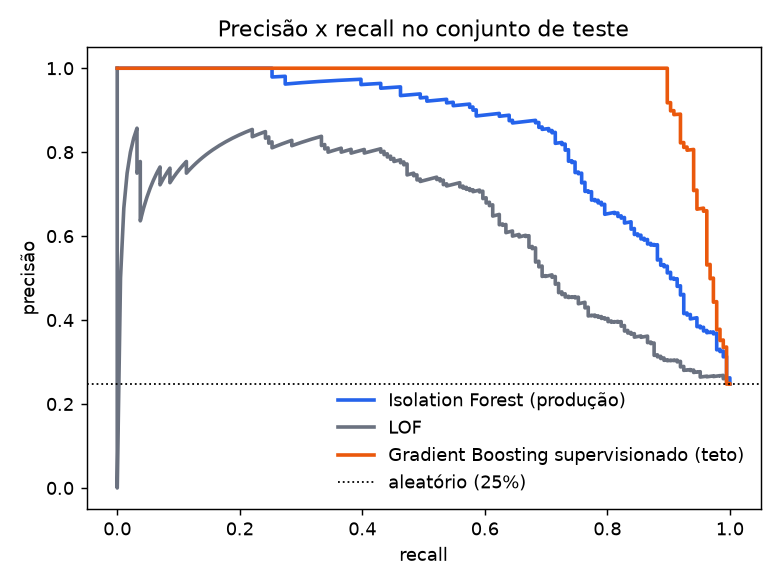

In [4]:
from IPython.display import Image, display
display(Image(filename=str(REPORTS / "figures/pr_curves.png")))

## Recall por tipo de fraude
O modelo não pega todos os tipos igualmente — e isso orienta a próxima iteração.

,tipo_fraude,cartoes,detectados,recall,score_mediano
0,Desvio de finalidade,28,21,0.750,0.4795
1,Venda de créditos,27,19,0.704,0.4905
2,Clonagem,28,18,0.643,0.4762
3,Replay,29,17,0.586,0.4688
4,Uso em férias,27,13,0.481,0.4644
5,Uso offline,25,12,0.480,0.4617
6,Recarga clandestina,30,13,0.433,0.4602
7,Uso em licença,28,10,0.357,0.4536
8,Conluio operacional,21,7,0.333,0.4613
9,Empréstimo do cartão,21,5,0.238,0.4425


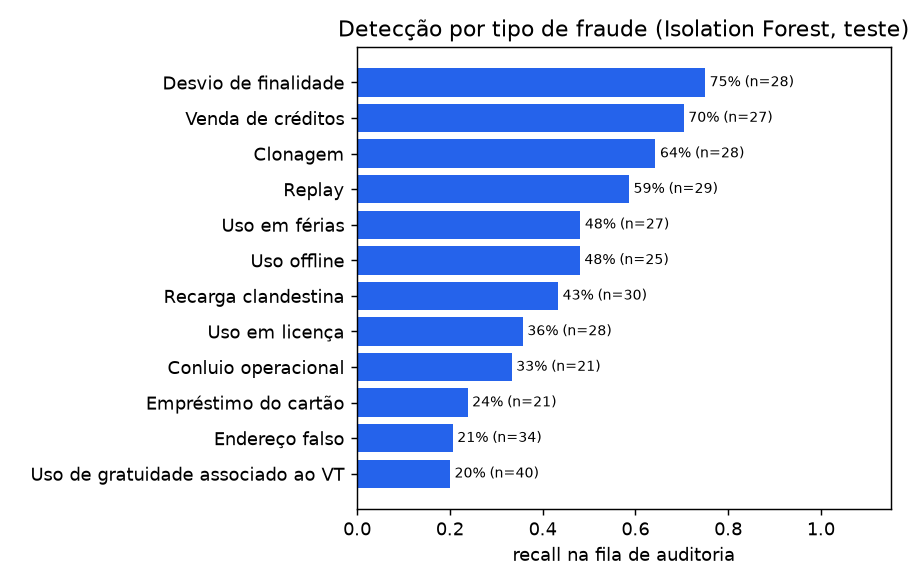

In [5]:
por_tipo = pd.read_csv(REPORTS / "recall_por_tipo.csv")
display(por_tipo)
display(Image(filename=str(REPORTS / "figures/recall_por_tipo.png")))

## Tamanho da fila de auditoria x resultado
Quantos cartões revisar? Precisão e recall em função da fila (score final, todos os cartões).

,fila_pct,precisao,recall
124,0.05,1.000,0.202
249,0.10,0.984,0.397
499,0.20,0.876,0.708
749,0.30,0.703,0.851


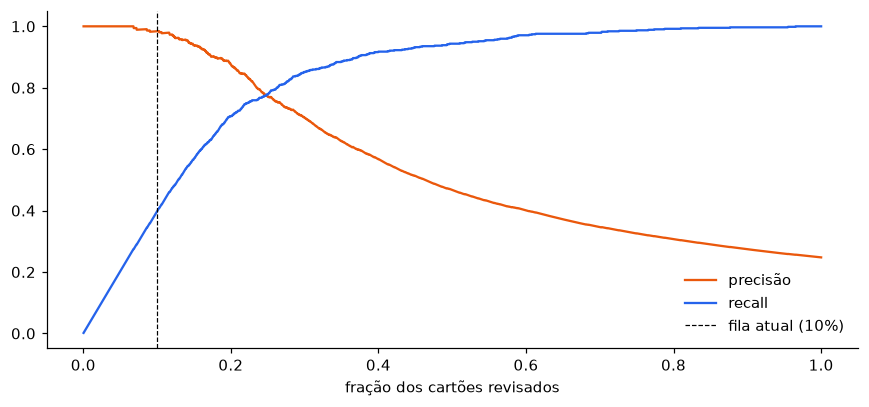

In [6]:
s = pd.read_parquet(GOLD / "card_scores.parquet").sort_values("anomaly_score", ascending=False)
k = np.arange(1, len(s) + 1)
acertos = s.is_fraude.cumsum().to_numpy()
curva = pd.DataFrame({"fila_pct": k / len(s), "precisao": acertos / k, "recall": acertos / s.is_fraude.sum()})
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curva.fila_pct, curva.precisao, label="precisão", color="#EA580C")
ax.plot(curva.fila_pct, curva.recall, label="recall", color="#2563EB")
ax.axvline(0.10, color="black", ls="--", lw=0.8, label="fila atual (10%)")
ax.set_xlabel("fração dos cartões revisados"); ax.legend(frameon=False); plt.tight_layout()
curva.iloc[[int(len(s) * f) - 1 for f in (0.05, 0.10, 0.20, 0.30)]].round(3)

Obs.: esta curva usa o modelo final (treinado em todos os cartões, **sem rótulo**) — o número honesto
é o do conjunto de teste acima; aqui interessa a *forma* do trade-off para decidir o tamanho da fila.

## Por que um cartão foi sinalizado? (SHAP)

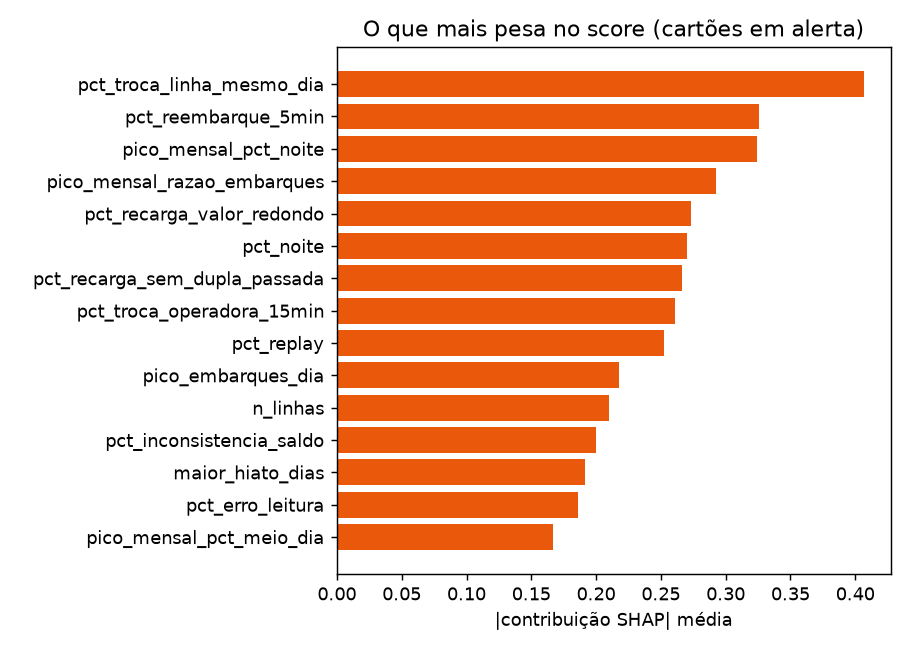

,rank,nome,classe,tipos_fraude,principais_motivos
0,1,LARISSA RIBEIRO MENDES,Fraudulento,Clonagem|Desvio de finalidade|Replay,"reembarques em menos de 5 min (valor 0.0519, +..."
1,2,VINÍCIUS ALMEIDA ROCHA,Fraudulento,Clonagem,troca de operadora em menos de 15 min (valor 0...
2,3,MARIANA OLIVEIRA CAVALCANTI,Fraudulento,Recarga clandestina|Clonagem|Desvio de finalidade,"recargas de valor redondo (valor 0.2101, +1.24..."
3,4,OLÍVIA TEIXEIRA NOGUEIRA,Fraudulento,Desvio de finalidade,"embarques à noite (valor 0.0842, +1.449); pior..."
4,5,OLÍVIA TEIXEIRA PEREIRA,Fraudulento,Clonagem,troca de operadora em menos de 15 min (valor 0...
5,6,ANA TEIXEIRA SOUZA,Fraudulento,Clonagem,troca de operadora em menos de 15 min (valor 0...
6,7,PAULO OLIVEIRA NOGUEIRA,Fraudulento,Venda de créditos|Recarga clandestina,"recargas fora da dupla passada (valor 0.2128, ..."
7,8,RAFAELA MOREIRA LIMA,Fraudulento,Desvio de finalidade|Uso em férias,embarques em linha intermunicipal (valor 0.061...


In [7]:
display(Image(filename=str(REPORTS / "figures/shap_importancia.png")))
alertas = pd.read_csv(REPORTS / "alertas_explicados.csv")
alertas[["rank", "nome", "classe", "tipos_fraude", "principais_motivos"]].head(8)

## Perfis de uso (clusters)

In [8]:
print("k escolhido:", m["clusters"]["k"], "| silhouette:", m["clusters"]["silhouette"])
pd.read_csv(REPORTS / "clusters_perfil.csv")

k escolhido: 4 | silhouette: {'3': 0.1835, '4': 0.185, '5': 0.1383, '6': 0.1461, '7': 0.1543, '8': 0.1183}


,cluster,cartoes,embarques_por_dia_ativo,pct_dias_ativos,pct_linha_principal,n_linhas,pct_fim_semana,pct_noite,pct_meio_dia,maior_hiato_dias,saldo_medio,taxa_fraude
0,0,1538,2.064,0.804,0.971,2.0,0.311,0.003,0.016,6.0,143.558,0.124
1,1,311,2.070,0.805,0.354,9.0,0.305,0.003,0.027,6.0,142.846,0.277
2,2,425,2.070,0.440,0.892,2.0,0.281,0.003,0.049,10.0,84.664,0.275
3,3,226,2.189,0.804,0.898,10.0,0.307,0.008,0.049,6.0,153.081,1.000


### Leitura para a entrevista

- **Isolation Forest vs teto supervisionado**: a distância entre os dois mostra quanto sinal ainda não é
  capturado sem rótulo — argumento para, em produção, usar o feedback da auditoria como rótulo e evoluir
  para um modelo semi/supervisionado.
- **Fila de auditoria** é a métrica de negócio: precisão@k = retrabalho do time; recall@k = fraude capturada.
- **Explicação por cartão** (SHAP) transforma um score em um motivo acionável para o auditor.